# AP 155 Lab Exercise
---
## Exercise 7: Root Finding

_Instructions_: 
- **Report figure:** (See Problem) Plot the convergence of the values towards the root of $f(x)$. That is, plot $x_i$ vs. $i$ for each of the four methods ($x_i$ is the output of the method on the $i$th step). Overlay the convergence curves on a single plot and check the convergence. You may have more than four curves; for instance, you could have used newton's method twice for two different guesses. Make sure to label your curves (method + initial guesses).
- **Report discussion:**
    - Explain the report figure.
    - What are the advantages and disadvantages of the root-finding methods?
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: 
- _Student No._: 20XX-XXXXX
- _Section_: THR-TX-X

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view?usp=sharing) (Note: percentages may still be tweaked)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_:_

---
## Section 1: Report

### Report figure

<img src="figures/cat.jpg" alt="Alt text" width=45%> <img src="figures/cat.jpg" alt="Alt text" width=45%>


EDIT ME. See instruction above for what to include. Insert caption here, a short description what the figure illustrates. The syntax in markdown for putting a figure is `![Description](local_file_name.png)` or `<img src="/path/to_image.jpg" alt="Alt text" width=45%>`. Make sure the figure has complete elements.


### Report discussion

#### Root Finding
For an arbitrary function it may be important to find its roots $x_0$ such that $f(x_0) = 0$. In general there is no single method to find every root for every function, or even to determine whether every root has been found if any exist at all. There are various numerical methods to go about root finding, each with its strengths and limitations. Here we detail four such methods.

#### Fixed Point Method
Given some function with root $f(x_0)=0$, we can find some other function derived from $f$ called $g(x)$ such that $g(x_0)=x_0$. These $x_0$ are "fixed points", and by applying $x_1 = g(x_0)$ for some initial guess $x_0$, we may converge towards the fixed point. 

However, there are some caveats. Note that $g(x)$ is not unique. In our case, we used 
$$g(x)=\frac{8-4e^x}{-x^4+4x^3-4x^2+xe^x-2x-4e^x+8}$$
and found that the only root converged to is $x_0=2$.
This is because, to converge to a root using fixed point method, it must be the case that $|g'(x_0)|<1$. Otherwise, the series diverges from the root instead.

#### Bisection Method
This method takes a region with bounds $x_0$ and $x_1$, where one is positive and one is negative. For continuous functions, this guarantees that a root exists within the bound. Bisecting the bound, we choose the half with new bounds that still maintain opposite signs. Doing this repeatedly allows finding the root to arbitrary precision. 

However, there are edge cases to worry about. The region may contain more than one root. More importantly, this method cannot find roots that just 'kiss' the y-axis, where because the function never crosses the y-axis, the bisection of bounds never approaches the root. In our case, it is unable to find the root $x_0 = 2$.

#### Newton Method
Newton's method requires the evaluation of a derivative. It converges quite reliably and is not subject to the limitations of the prior methods, however errors due to derivative evaluation are inevitably introduced. It is also quite computationally intensive.

#### Secant Method
Secant method reduces the computational intensity of Newtob's method and does away with the need to evaluate a derivative in exchange for needing two initial guesses, $x_0$ and $x_1$. In my implementation of secant method I ran into a catastrophic problem. The denominator term is prone to subtractive cancellation, and Ive had to slice my data to remove divide by zero instances. The convergence may also be erratic for particular initial guesses.

### Other comments
- Sorry sa late sir (╥﹏╥) may exam ako sa thursday then 2 exams on tuseday
- No AI for any of the code, writing, or proofreading

---
## Section 2: Code

### Problem 1: Root Finding


Implement root finders *manually* to find the roots of an arbitrary function

1. fixed-point method (relaxation, needs an initial guess)
2. bisection method (bracketing, needs two bounds)
3. newton's method (known derivative, needs an initial guess)
4. secant method (approximate derivative, needs two initial guesses)

Consider the function

$$
f(x) = -x^5 + 4x^4 - 4x^3 + x^2 e^x - 2x^2 -4xe^x + 8x + 4e^x -8
$$

5. Plot the function from x=-2 to x=5. You may want to "enlarge" the plot by rescaling/"cropping" the y-axis. You should be able to estimate where the roots are approximately
   
6. Find the roots of $f(x)$ by implementing the four methods shown.

7. Report Figure: Plot the convergence of the values towards the root of $f(x)$. That is, plot $x_i$ vs. $i$ for each of the four methods ($x_i$ is the output of the method on the $i$th step). Overlay the convergence curves on a single plot and check the convergence. You may have more than four curves; for instance, you could have used newton's method twice for two different guesses. Make sure to label your curves (method + initial guesses).

In [1]:
import matplotlib.pyplot as plt
import numpy as np

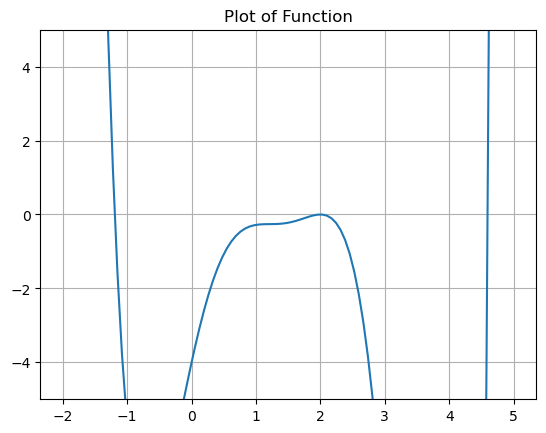

In [4]:
# function plotting
def func(xs):
    return -xs**5 + 4*xs**4 -4*xs**3 + (xs**2)*(np.exp(xs)) -2*xs**2-4*xs*np.exp(xs) +8*xs +4*np.exp(xs) - 8

xs = np.linspace(-2,5, num=100)
zero = np.zeros(100)
ys = func(xs)



fig, ax = plt.subplots()
ax.plot(xs,ys)

ax.set_title("Plot of Function")
ax.set_ylim(-5,5)
ax.grid()

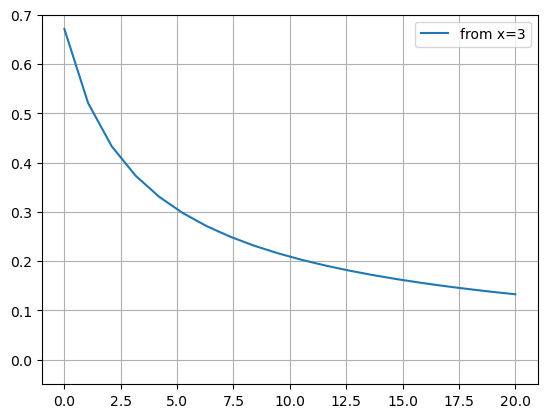

In [16]:
# fixed-point method

def gfunc(xs):
    #return -xs**5 + 4*xs**4 -4*xs**3 + (xs**2)*(np.exp(xs)) -2*xs**2-4*xs*np.exp(xs) +9*xs +4*np.exp(xs) - 8
    return (8-4*np.exp(xs))/(-xs**4 + 4*xs**3 - 4*xs**2 + xs*np.exp(xs)-2*xs-4*np.exp(xs)+8)




fp_x_0 = 3

def fixed_point(x):

    fp_container = np.array([])
    
    for i in range(20):
        x = gfunc(x)
        fp_container = np.append(fp_container, [x])
        
    return fp_container


#plotting
fig1, ax1 = plt.subplots()
x_axis = np.linspace(0,20, num=20)

ax1.plot(x_axis, fixed_point(3)-2,
        label="from x=3")
ax1.grid()
ax1.set_ylim(-0.05,0.7)
ax1.legend()

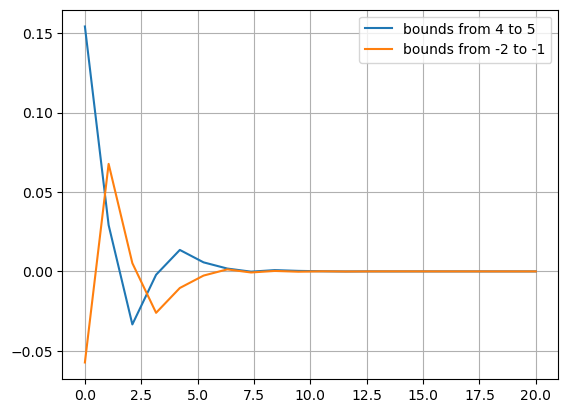

In [17]:
# bisection method


def bisection(bound1, bound2):
    bs_container = np.array([])
    
    for i in range(20):
        if func(bound1)*func(0.5*(bound1+bound2)) < 0:
            bound1 = bound1
            bound2 = 0.5*(bound1+bound2)
            bs_container = np.append(bs_container, [0.5*(bound1+bound2)])
        
        else:
            if func(0.5*(bound1+bound2))*func(bound2) < 0:
                bound1 = 0.5*(bound1+bound2)
                bound2 = bound2
                bs_container = np.append(bs_container, [0.5*(bound1+bound2)])
    
            else:
                print("invalid bounds")
                break
    return bs_container



#plotting

fig2, ax2 = plt.subplots()
x_axis = np.linspace(0,20, num=20)

ax2.plot(x_axis, bisection(4,5)-4.59586382,
        label="bounds from 4 to 5")
ax2.plot(x_axis, bisection(-2,-1)+1.1926856,
        label="bounds from -2 to -1")
ax2.grid()
ax2.legend()

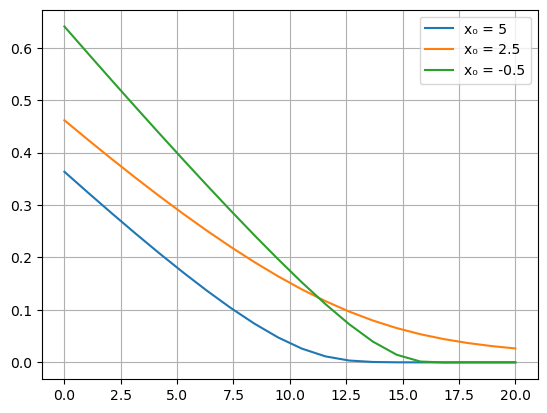

In [21]:
# newton's method

def newton(dx, xes):
    nm_container = np.array([])
    for i in range(20):
        xes = -func(xes)/((func(xes)+func(xes+dx))/dx)+xes
        nm_container = np.append(nm_container, xes)
        
    return nm_container

#plotting

fig3, ax3 = plt.subplots()
x_axis = np.linspace(0,20, num=20)

ax3.plot(x_axis, newton(0.1, 5)-4.59586382,
        label="x\u2080 = 5")
ax3.plot(x_axis, newton(0.1, 2.5)-2,
        label ="x\u2080 = 2.5")
ax3.plot(x_axis, newton(0.1, -0.5)+1.1926856,
        label="x\u2080 = -0.5")
ax3.grid()
ax3.legend()

[4.93053044 4.87657771 4.69875336 4.63259834 4.60172919 4.59622951
 4.59586734 4.59586357 4.59586356 4.59586356 4.59586356 4.59586356
 4.59586356        nan        nan        nan        nan        nan
        nan        nan]


/tmp/ipykernel_616/3508898498.py:6: RuntimeWarning: invalid value encountered in scalar divide
  n = x_0-func(x_0)*(x_0-x_1)/(func(x_0)-func(x_1))


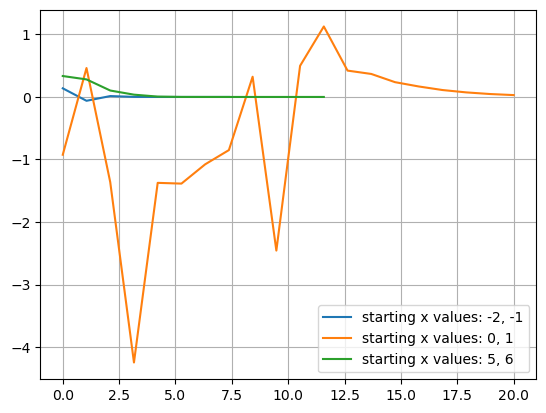

In [24]:
# secant method

def secant(x_0, x_1):
    sc_container = np.array([])
    for i in range(20):
        n = x_0-func(x_0)*(x_0-x_1)/(func(x_0)-func(x_1))
        x_0 = x_1
        x_1 = n
        sc_container = np.append(sc_container, n)
    return sc_container

print(secant(5,6))

fig4, ax4 = plt.subplots()
x_axis = np.linspace(0,20, num=20)

ax4.plot(x_axis[:8], secant(-2,-1)[:8]+1.1926856,
        label="starting x values: -2, -1")
ax4.plot(x_axis, secant(0,1)-2,
        label="starting x values: 0, 1")
ax4.plot(x_axis[:12], secant(5,6)[:12]-4.59586382,
        label="starting x values: 5, 6")
ax4.grid()
ax4.legend()

#### Problem 1 code summary

For all plots, I chose to have all graphs converge to y=0 (by subtracting the root being converged towards from y) so that the behavior of each approach per iteration can be easily compared.

---